In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from linearmodels import IV2SLS
from scipy import stats
import statsmodels.api as sm
df = pd.read_csv("data/cars.csv")

# Problem 1 - Indledende analyse

#### 1A)


Deskriptiv statistik: Car


,mean,std,10%,50%,90%
Pris ($10.000),35.851,18.755,17.523,30.428,62.019
Markedsandel (%),0.129,0.182,0.003,0.058,0.343
Hestekræfter,178.212,83.409,90.000,160.000,300.000
MPG,22.673,6.820,17.000,21.000,30.000
Footprint,12870.079,1710.411,10730.060,12842.265,14996.505
Vægt,3181.940,639.508,2348.000,3209.250,3992.500



Deskriptiv statistik: Van


,mean,std,10%,50%,90%
Pris ($10.000),31.452,5.527,23.784,31.902,37.758
Markedsandel (%),0.159,0.161,0.009,0.096,0.396
Hestekræfter,188.484,63.897,106.000,180.000,283.000
MPG,17.896,5.053,14.000,17.000,21.000
Footprint,15183.681,1879.778,12771.684,15316.570,17740.801
Vægt,4274.879,794.009,3370.000,4247.250,5426.600



Deskriptiv statistik: SUV


,mean,std,10%,50%,90%
Pris ($10.000),40.414,14.940,24.411,37.323,61.932
Markedsandel (%),0.114,0.150,0.006,0.061,0.290
Hestekræfter,232.332,74.918,141.000,231.000,325.000
MPG,18.007,4.978,13.000,17.000,23.950
Footprint,13790.904,1785.689,11630.205,13731.410,16081.560
Vægt,4246.049,854.302,3190.700,4181.750,5535.950



Deskriptiv statistik: Truck


,mean,std,10%,50%,90%
Pris ($10.000),27.809,9.819,17.005,25.473,41.131
Markedsandel (%),0.339,0.433,0.006,0.164,1.007
Hestekræfter,189.166,90.310,90.000,160.000,330.000
MPG,17.832,4.359,13.500,17.000,23.000
Footprint,15086.141,2478.911,11761.629,15042.260,18377.000
Vægt,4043.420,1114.944,2709.300,3905.000,5735.400


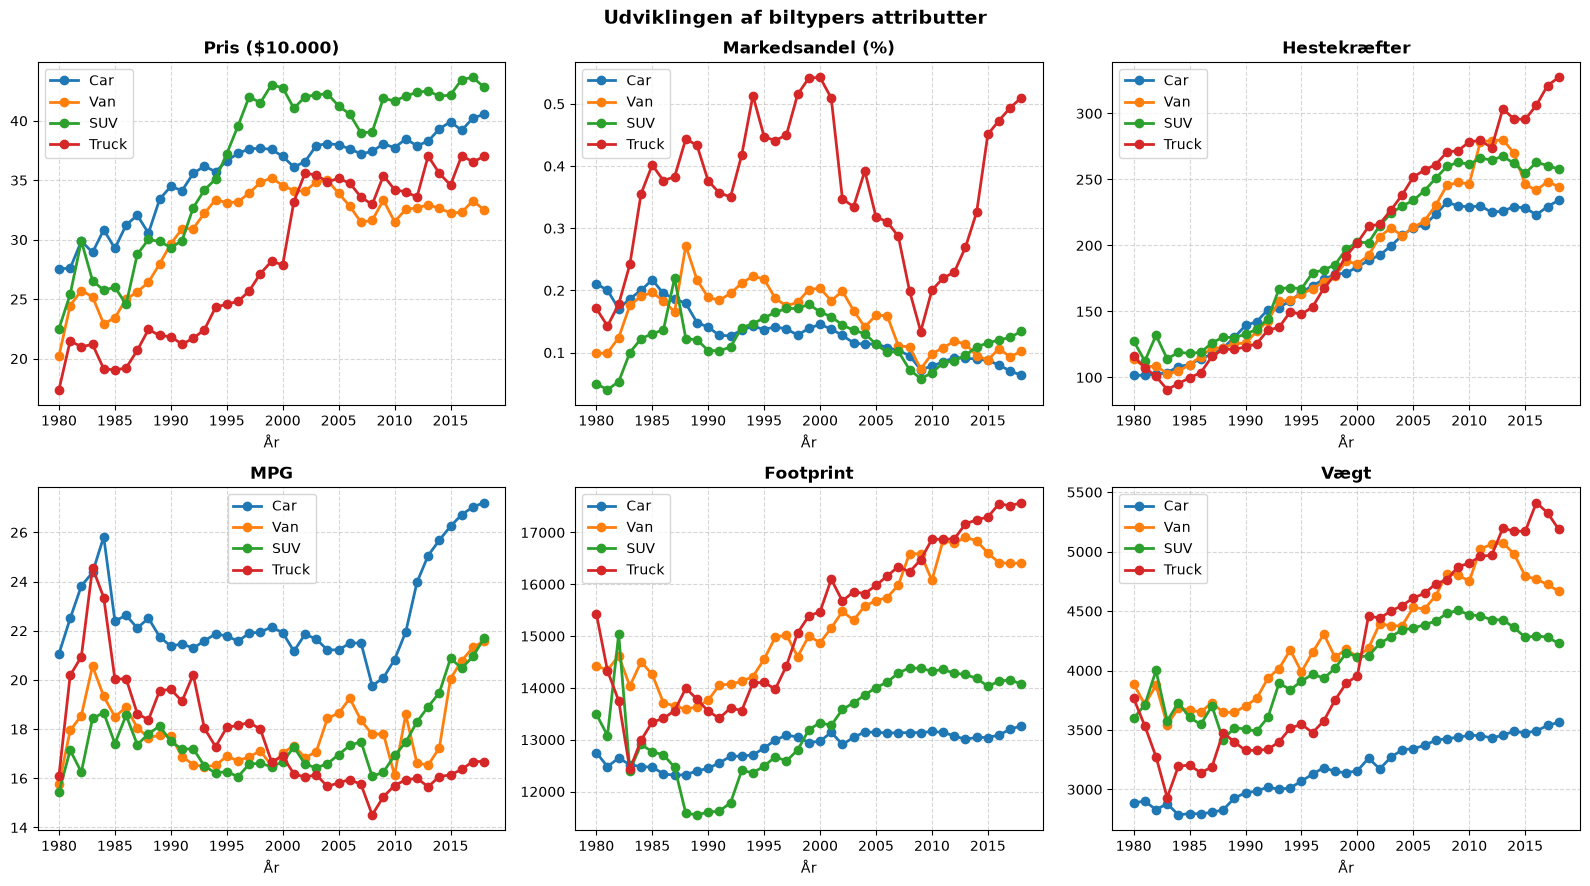

In [31]:
# Deskriptiv statistik for priser, markedsandele og produktegenskaber
# Markedsandel i procent
df['market_share_pct'] = 100 * df['market_share']

# Variabler, der skal beskrives
desc_vars = [
    'price', 'market_share_pct', 'hp',
    'mpg', 'footprint', 'weight'
]

# Navne til tabellen
var_names = [
    'Pris ($10.000)', 'Markedsandel (%)', 'Hestekræfter',
    'MPG', 'Footprint', 'Vægt'
]

# Opret biltyper, hvis det ikke allerede er gjort
df['car_type'] = 'Car'
df.loc[df['van'] == 1, 'car_type'] = 'Van'
df.loc[df['suv'] == 1, 'car_type'] = 'SUV'
df.loc[df['truck'] == 1, 'car_type'] = 'Truck'

# Beregn deskriptiv statistik for hver biltype
for car_type in ['Car', 'Van', 'SUV', 'Truck']:
    print(f'\nDeskriptiv statistik: {car_type}')

    descriptive = (
        df.loc[df['car_type'] == car_type, desc_vars]
        .describe(percentiles=[0.1, 0.5, 0.9])
        .T
    )

    descriptive.index = var_names

    display(
        descriptive[['mean', 'std', '10%', '50%', '90%']]
        .round(3)
    )

# Vis udviklingen over tid i priser, markedsandele og andre produktegenskaber
# Gennemsnit pr. år for desc_vars
yearly = df.groupby('year')[desc_vars].mean()

titles = ['Pris ($10.000)', 'Markedsandel (%)', 'Hestekræfter', 'MPG', 'Footprint', 'Vægt']

car_types = ['Car', 'Van', 'SUV', 'Truck']

# Gennemsnit pr. år og biltype
yearly_type = (
    df.groupby(['year', 'car_type'])[desc_vars]
      .mean()
      .reset_index()
)

# Tegn de seks grafer
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, var in enumerate(desc_vars):
    for car_type in car_types:
        subset = yearly_type[
            yearly_type['car_type'] == car_type
        ]

        axes[i].plot(
            subset['year'],
            subset[var],
            marker='o',
            linewidth=2,
            label=car_type
        )

    axes[i].set_title(titles[i], fontweight='bold')
    axes[i].set_xlabel('År')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend()
fig.suptitle(
    'Udviklingen af biltypers attributter',
    fontsize=14, fontweight='bold'
)
plt.tight_layout()
plt.show()


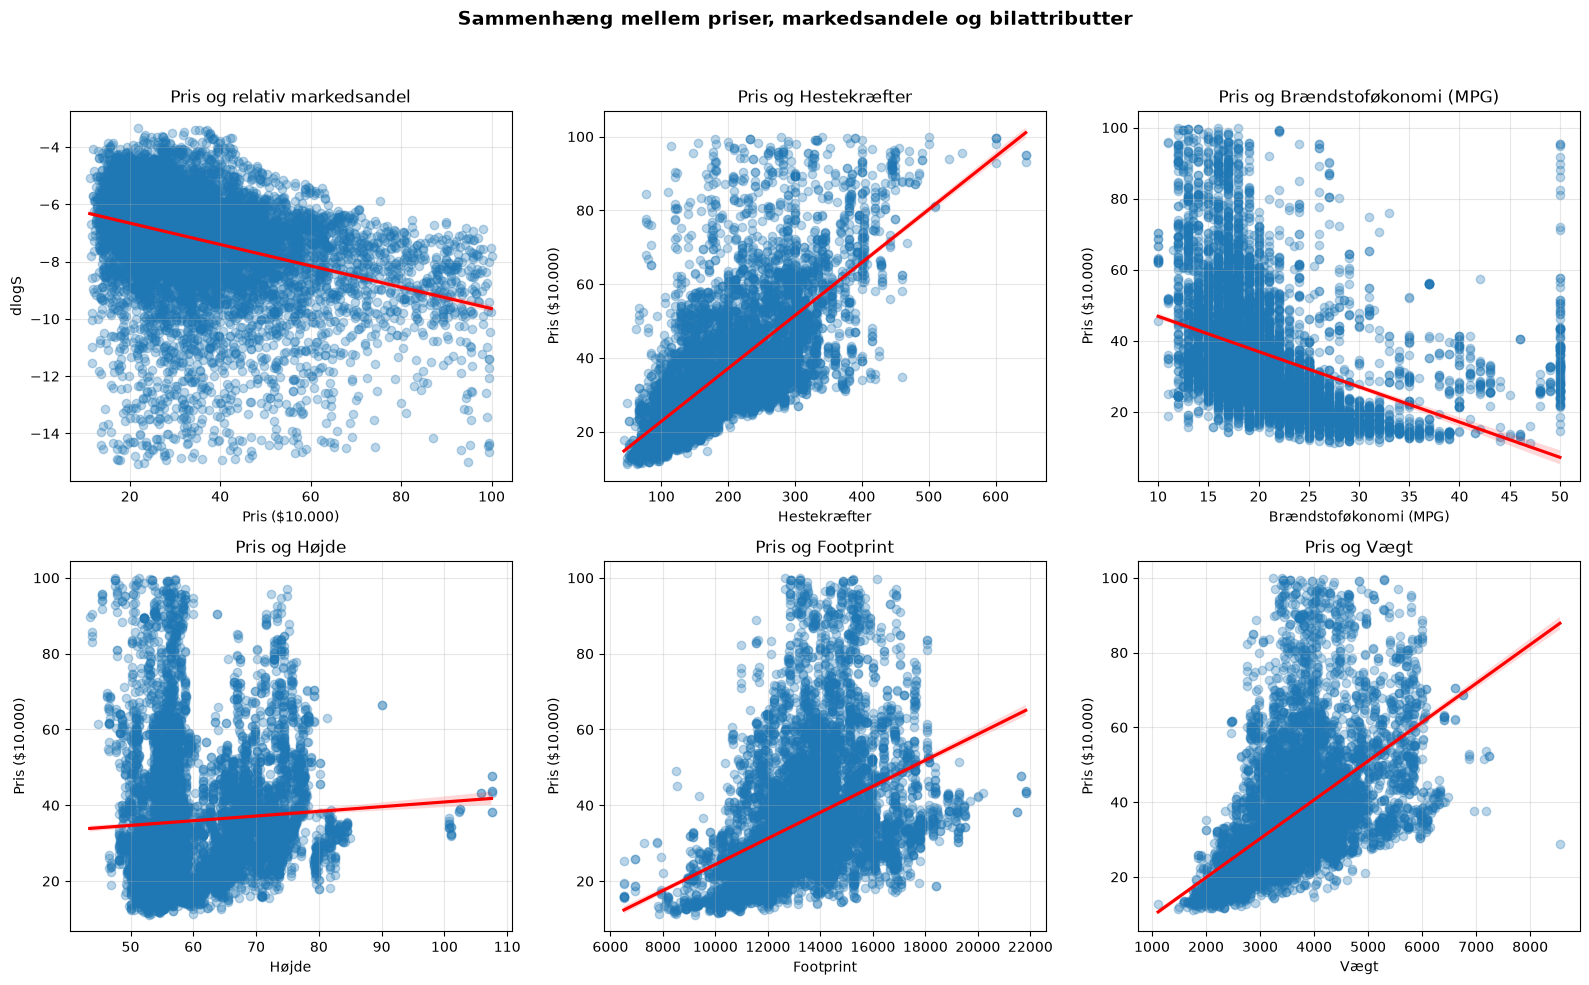

In [32]:
physical_vars = ['hp', 'mpg', 'height', 'footprint', 'weight']
titles = [
    'Hestekræfter',
    'Brændstoføkonomi (MPG)',
    'Højde',
    'Footprint',
    'Vægt'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

# 1. Markedsandel først
sns.regplot(
    data=df, x='price', y='dlogS', ax=axes[0],
    scatter_kws={'alpha': 0.3},
    line_kws={'color': 'red'}
)

axes[0].set_xlabel('Pris ($10.000)')
axes[0].set_ylabel('dlogS')
axes[0].set_title('Pris og relativ markedsandel')
axes[0].grid(True, alpha=0.3)

# 2-6. Fysiske attributter
for i, var in enumerate(physical_vars):
    ax = axes[i + 1]

    sns.regplot(
        data=df, x=var, y='price', ax=ax,
        scatter_kws={'alpha': 0.3},
        line_kws={'color': 'red'}
    )

    ax.set_xlabel(titles[i])
    ax.set_ylabel('Pris ($10.000)')
    ax.set_title(f'Pris og {titles[i]}')
    ax.grid(True, alpha=0.3)

fig.suptitle(
    'Sammenhæng mellem priser, markedsandele og bilattributter',
    fontsize=14, fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

#### 1B)

In [33]:
df = pd.read_csv("data/cars.csv")
# Specifikation 1
df['const'] = 1

S1 = sm.OLS(df['dlogS'], df[['const','price']]).fit(cov_type='HC1',use_t=True)

# Specifikation 2
Xkon = ['hp','mpg','height','footprint','weight','number_trims']
Xcardummy = ['releaseYear','yearsSinceDesign','sport','EV','truck','suv','van']
Xvar = Xkon + Xcardummy

exog_vars2 =  ['const'] + Xvar + ['price']
S2 = sm.OLS(df['dlogS'], df[exog_vars2]).fit(cov_type='HC1',use_t=True)

# Specifikation 3
# Tilføjer årsdummies
year_dummies = pd.get_dummies(df['year'], prefix='y', drop_first=True, dtype=int) # Referance året er 1980. 
df = pd.concat([df, year_dummies], axis=1)
# Store year variable names for later use
years = list(year_dummies.columns) # ['y_1981', 'y_1982', ...]


exog_vars3 = exog_vars2 + years
S3 = sm.OLS(df['dlogS'], df[exog_vars3]).fit(cov_type='HC1',use_t=True)

# Specifikation 4
for var in Xkon:
    df[f'{var}_log'] = np.log(df[var])

Xkon_log = [f'{var}_log' for var in Xkon]

exog_vars4 = ['const'] + Xkon_log + Xcardummy + ['price'] + years

S4 = sm.OLS(df['dlogS'], df[exog_vars4]).fit(cov_type='HC1',use_t=True)

In [34]:

import pandas as pd

models = [S1, S2, S3, S4]
model_names = ['Model 1', 'Model 2', 'Model 3', 'Model 4']

# Car type-dummies, som samles i én række
car_type_dummies = ['sport', 'EV', 'truck', 'suv', 'van']

# Alle almindelige forklarende variable
# Udelader const, årsdummies og car type-dummies
regular_vars = list(dict.fromkeys(
    var
    for model in models
    for var in model.model.exog_names
    if var != 'const'
    and var not in years
    and var not in car_type_dummies
))

# Formatér estimat og standardfejl
def format_coef(model, var):
    if var not in model.params.index:
        return ""
    return f"{model.params[var]:.4f} ({model.bse[var]:.4f})"

# Opret tabel
table = pd.DataFrame(index=regular_vars, columns=model_names)

for model, name in zip(models, model_names):
    table[name] = [
        format_coef(model, var)
        for var in regular_vars
    ]

# Samlet række for car type-dummies
table.loc['Car type-dummies'] = [
    'Ja' if any(
        var in model.model.exog_names
        for var in car_type_dummies
    ) else 'Nej'
    for model in models
]

# Samlet række for årsdummies
table.loc['Års-dummies'] = [
    'Ja' if any(
        var in model.model.exog_names
        for var in years
    ) else 'Nej'
    for model in models
]

# Modelstatistikker
table.loc['R²'] = [f"{m.rsquared:.4f}" for m in models]
table.loc['SSR'] = [f"{m.ssr:.4f}" for m in models]
table.loc['SST'] = [f"{m.centered_tss:.4f}" for m in models]
table.loc['SSE (forklaret sum af kvadrater)'] = [
    f"{m.ess:.4f}" for m in models
]

table.index.name = 'Forklarende variabel'

# Vis hele tabellen uden at afkorte rækkerne
with pd.option_context('display.max_rows', None):
    display(table)


,Model 1,Model 2,Model 3,Model 4
Forklarende variabel,,,,
price,-0.0373 (0.0010),-0.0243 (0.0016),-0.0370 (0.0017),-0.0298 (0.0014)
hp,,-0.0038 (0.0004),0.0024 (0.0005),
mpg,,-0.0427 (0.0037),-0.0115 (0.0044),
height,,-0.0237 (0.0051),-0.0154 (0.0050),
footprint,,0.0004 (0.0000),0.0003 (0.0000),
weight,,-0.0007 (0.0001),-0.0006 (0.0001),
number_trims,,0.0552 (0.0039),0.0530 (0.0039),
releaseYear,,-1.0643 (0.0586),-1.2272 (0.0573),-0.5031 (0.0536)
yearsSinceDesign,,-0.1269 (0.0074),-0.1278 (0.0073),-0.1077 (0.0061)


#### 1C) - T-test Robuste standardfejl

In [35]:
#robuste std fejl
print(S1.t_test('price = 0'))
print(S2.t_test('price = 0'))
print(S3.t_test('price = 0'))
print(S4.t_test('price = 0'))

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0373      0.001    -35.756      0.000      -0.039      -0.035
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0243      0.002    -15.013      0.000      -0.027      -0.021
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0370      0.002    -21.818      0.000      -0.040      -0.034
                             Test for Constraints   

#### 1C) - T-test normale standardfejl

In [36]:
#Normale standardfejl

S1_std = sm.OLS(df['dlogS'], df[['const','price']]).fit(use_t=True)
S2_std = sm.OLS(df['dlogS'], df[exog_vars2]).fit(use_t=True)
S3_std = sm.OLS(df['dlogS'], df[exog_vars3]).fit(use_t=True)
S4_std = sm.OLS(df['dlogS'], df[exog_vars4]).fit(use_t=True)

print(S1_std.t_test('price = 0'))
print(S2_std.t_test('price = 0'))
print(S3_std.t_test('price = 0'))
print(S4_std.t_test('price = 0'))


                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0373      0.001    -33.935      0.000      -0.039      -0.035
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0243      0.002    -15.057      0.000      -0.027      -0.021
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0370      0.002    -21.903      0.000      -0.040      -0.034
                             Test for Constraints   

# Problem 2

#### 2A) 

In [45]:
# Tilføjer make-dummies
make_dummies = pd.get_dummies(df['make'], prefix='make', dtype=int)

# Udelader Volvo som referencekategori
make_dummies = make_dummies.drop(columns=['make_volvo'])
df = pd.concat([df, make_dummies], axis=1)
makes = list(make_dummies.columns)

Xpro = Xkon_log + Xcardummy # produktkarakteristika(log) + bil-type dummies
X5 = ['const']+ Xpro + ['price'] + years + makes # Xpro + års-dummies + make-dummies

result4 = sm.OLS(df['dlogS'],df[X5]).fit(cov_type='HC1')

df_within = df.copy()
vars_to_transform = [['dlogS'], Xpro, ['price'], years] 
for var in vars_to_transform:
    make_mean = df.groupby('make')[var].transform('mean')
    df_within[var] = df[var] - make_mean

X_within = Xpro + ['price'] + years

result5 = sm.OLS(df_within['dlogS'],df_within[X_within]).fit(cov_type='HC1')




# Problem 4 - Monte Carlo simulation

In [38]:
def simulate(gamma0,gamma1,gamma2):
    #definer parameter værdier
    n = 500 
    beta0 = 0.5
    beta1 = -0.1
    z = np.random.normal(loc = 0, scale = 1, size = n)
    xi = np.random.normal(loc = 0, scale = 1, size = n)
    v = np.random.normal(loc = 0, scale = 1, size = n)
    eta0 = (gamma0 - beta0) / (beta1 - gamma1)
    eta1 = gamma2 / (beta1 - gamma1)
    u = (v - xi) / (beta1 - gamma1)
    p = eta0 + eta1*z + u 
    y = beta0 + beta1*p + xi

    # Opretter dataframe med estimeret værdier
    df = pd.DataFrame({
        'y': y,
        'z': z,
        'p': p
    })
    # Estimere med OLS
    result_OLS = smf.ols('y ~ p', data = df).fit()
    beta1_OLS = result_OLS.params['p']

    # Estimere modellen med IV2SLS, z bruges som instrument for p 

    result_IV = IV2SLS.from_formula('y ~ 1 + [p ~ z]', data = df).fit()
    beta1_IV = result_IV.params['p']
    return beta1_OLS, beta1_IV

def monte_carlo(reps=500):
    np.random.seed(0)
    #Gemmer OLS resultater
    OLS_result_S1 =[]
    OLS_result_S2 =[]
    OLS_result_S3 =[]
    #Gemmer IV resultater
    IV_result_S1 = []
    IV_result_S2 = []
    IV_result_S3 = []
    for r in range(reps):
        beta1_OLS_S1, beta1_IV_S1 = simulate(gamma0=0.25,gamma1=1,gamma2=1) # S1
        beta1_OLS_S2, beta1_IV_S2 = simulate(gamma0=0.25,gamma1=1,gamma2=0.25) # S2
        beta1_OLS_S3, beta1_IV_S3 = simulate(gamma0=0.25,gamma1=0.25,gamma2=1) # S3
        #Tilføj resultater til liste
        IV_result_S1.append(beta1_IV_S1)
        IV_result_S2.append(beta1_IV_S2)
        IV_result_S3.append(beta1_IV_S3)
        OLS_result_S1.append(beta1_OLS_S1)
        OLS_result_S2.append(beta1_OLS_S2)
        OLS_result_S3.append(beta1_OLS_S3)



    results = pd.DataFrame({'beta1_IV_S1': IV_result_S1,
                            'beta1_OLS_S1': OLS_result_S1,
                            'beta1_IV_S2': IV_result_S2,
                            'beta1_OLS_S2': OLS_result_S2,
                            'beta1_IV_S3': IV_result_S3,
                            'beta1_OLS_S3': OLS_result_S3,
                            })

    return results


results1 = monte_carlo()

In [39]:
# Beregner bias og varians for estimatorne
beta1_true = -0.1
bias = results1.mean() - beta1_true
varians = results1.var()

bias_varians = pd.DataFrame({
    'Bias': bias,
    'Varians': varians
})




print(bias_varians)

                  Bias   Varians
beta1_IV_S1  -0.000081  0.002395
beta1_OLS_S1  0.368325  0.000515
beta1_IV_S2  -0.053499  0.056139
beta1_OLS_S2  0.532897  0.000611
beta1_IV_S3  -0.000063  0.000257
beta1_OLS_S3  0.116365  0.000052
